**Objetivo:** estimar el RUL (Remaining Useful Life) en ciclos solo con datos historicos
**Train y test:** train llega hasta la falla, test se corta antes 
**Degradacion:** Crece de forma exponencial y varia por motor -> Conviene un modelo no lineal, y el desgaste inicial distinto impide usar solo cycle
**Ruido:** Hay ruido de proceso y medicion, y la degradacion no siempre es monotona -> Sliding windows para el suavizado de sensores
**Condiciones de vuelo:** Altitud, Mach y TRA afectan los margenes de operacion -> Normalizar segun la condicion de operacion
**Indice de salud:** No se entrega a los participanetes -> No puede ser una variable de entrada
**Metrica:** Score asimetrico: predecir tarde se penaliza mas -> reportarlo junto con RMSE

### Dataset Column Structure

Each CSV file contains 27 columns representing snapshots of data taken during individual operational cycles:

- engine: Unit identifier number
- cycle: Time recorded in operational cycles
- op_setting_1: Operational setting 1
- op_setting_2: Operational setting 2
- op_setting_3: Operational setting 3
- Fan inlet temperature (°R) (T2): Sensor measurement 1
- LPC outlet temperature (°R) (T24): Sensor measurement 2
- HPC outlet temperature (°R) (T30): Sensor measurement 3
- LPT outlet temperature (°R) (T50): Sensor measurement 4
- Fan inlet Pressure (psia) (P2): Sensor measurement 5
- bypass-duct pressure (psia) (P15): Sensor measurement 6
- HPC outlet pressure (psia) (P30): Sensor measurement 7
- Physical fan speed (rpm) (Nf): Sensor measurement 8
- Physical core speed (rpm) (Nc): Sensor measurement 9
- Engine pressure ratio (P50/P2) (epr): Sensor measurement 10
- HPC outlet Static pressure (psia) (Ps30): Sensor measurement 11
- Ratio of fuel flow to Ps30 (pps/psia) (phi): Sensor measurement 12
- Corrected fan speed (rpm) (NRf): Sensor measurement 13
- Corrected core speed (rpm) (NRc): Sensor measurement 14
- Bypass Ratio (BPR): Sensor measurement 15
- Burner fuel-air ratio (farB): Sensor measurement 16
- Bleed Enthalpy (htBleed): Sensor measurement 17
- Required fan speed (Nf_dmd): Sensor measurement 18
- Required fan conversion speed (PCNfR_dmd): Sensor measurement 19
- High-pressure turbines Cool air flow (W31): Sensor measurement 20
- Low-pressure turbines Cool air flow (W32): Sensor measurement 21
- RUL: Remaining Useful Life (Target variable)

In [19]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib as plt
from pathlib import Path

DATOS = Path("CMAPSSData")
SUBSETS = ["FD001", "FD002", "FD003", "FD004"]

SENSORES = ["T2", "T24", "T30", "T50", "P2", "P15", "P30", "Nf", "Nc", "epr", "Ps30",
            "phi", "NRf", "NRc", "BPR", "farB", "htBleed", "Nf_dmd", "PCNfR_dmd",
            "W31", "W32"]
COLUMNAS = ["engine", "cycle", "op_setting_1", "op_setting_2", "op_setting_3"] + SENSORES

def cargar(split):
    partes = []
    for fd in SUBSETS:
        df = pd.read_csv(DATOS / f"{split}_{fd}.txt", sep=r"\s+", header=None, names=COLUMNAS)
        if split == "train":
            df["RUL"] = df.groupby("engine")["cycle"].transform("max") - df["cycle"]
        df.insert(0, "subset", fd)
        df.insert(1, "engine_id", fd + "_" + df["engine"].astype(str))
        partes.append(df)
    return pd.concat(partes, ignore_index=True)

def cargar_rul_test():
    partes = []
    for fd in SUBSETS:
        valores = pd.read_csv(DATOS / f"RUL_{fd}.txt", header=None).iloc[:, 0]
        ids = [f"{fd}_{i}" for i in range(1, len(valores) + 1)]
        partes.append(pd.Series(valores.values, index=ids))
    return pd.concat(partes).rename("RUL")

train = cargar("train")
test = cargar("test")
rul_test = cargar_rul_test()   # hoja de respuestas: usar solo para evaluar

assert train.shape == (160359, 29)
assert test.shape == (104897, 28)
assert "RUL" not in test.columns
assert train["engine_id"].nunique() == 709
assert test["engine_id"].nunique() == 707
assert not train.duplicated(["engine_id", "cycle"]).any()
assert not test.duplicated(["engine_id", "cycle"]).any()
assert (train.groupby("engine_id")["RUL"].min() == 0).all()
assert set(rul_test.index) == set(test["engine_id"])

In [27]:
train.shape

(160359, 29)

In [37]:
train.describe()

,engine,cycle,op_setting_1,op_setting_2,op_setting_3,T2,T24,T30,T50,P2,...,NRf,NRc,BPR,farB,htBleed,Nf_dmd,PCNfR_dmd,W31,W32,RUL
count,160359.000000,160359.000000,160359.000000,160359.000000,160359.000000,160359.000000,160359.000000,160359.000000,160359.000000,160359.000000,...,160359.000000,160359.000000,160359.000000,160359.000000,160359.000000,160359.000000,160359.000000,160359.000000,160359.000000,160359.000000
mean,105.553758,123.331338,17.211973,0.410004,95.724344,485.840890,597.361022,1467.035653,1260.956434,9.894999,...,2349.645243,8088.950972,9.054747,0.025185,360.698801,2273.754039,98.389146,25.942709,15.565700,122.331338
std,72.867325,83.538146,16.527988,0.367938,12.359044,30.420388,42.478516,118.175261,136.300073,4.265554,...,111.167242,80.623257,0.751581,0.004997,31.021430,142.513114,4.656270,11.691422,7.015067,83.538146
min,1.000000,1.000000,-0.008700,-0.000600,60.000000,445.000000,535.480000,1242.670000,1023.770000,3.910000,...,2027.570000,7845.780000,8.156300,0.020000,302.000000,1915.000000,84.930000,10.160000,6.010500,0.000000
25%,44.000000,57.000000,0.001300,0.000200,100.000000,449.440000,549.960000,1357.360000,1126.830000,5.480000,...,2387.970000,8070.530000,8.439250,0.020000,332.000000,2212.000000,100.000000,14.330000,8.601300,56.000000
50%,89.000000,114.000000,19.998100,0.620000,100.000000,489.050000,605.930000,1492.810000,1271.740000,9.350000,...,2388.070000,8118.590000,9.030100,0.030000,367.000000,2319.000000,100.000000,24.920000,14.953500,113.000000
75%,164.000000,173.000000,35.001500,0.840000,100.000000,518.670000,642.340000,1586.590000,1402.200000,14.620000,...,2388.160000,8139.410000,9.344200,0.030000,392.000000,2388.000000,100.000000,38.820000,23.294600,172.000000
max,260.000000,543.000000,42.008000,0.842000,100.000000,518.670000,645.110000,1616.910000,1441.490000,14.620000,...,2390.490000,8293.720000,11.066900,0.030000,400.000000,2388.000000,100.000000,39.890000,23.950500,542.000000


In [38]:
promedio = train["RUL"].mean()
print(f"El promedio de train a todos los motores es: {promedio:.2f}")

El promedio de train a todos los motores es: 122.33


In [57]:
train[SENSORES + ["RUL"]].nunique().sort_values()

farB             2
PCNfR_dmd        2
P2               6
T2               6
Nf_dmd           6
epr             21
P15             56
htBleed         58
RUL            543
NRf            567
W31            676
Ps30           771
Nf            1163
T24           1799
phi           5982
P30           6311
BPR          13124
T30          15377
NRc          20090
T50          20582
W32          26659
Nc           34161
dtype: int64

In [59]:
descriptivas = train[SENSORES + ["RUL"]].describe().T
descriptivas["asimetria"] = train[SENSORES + ["RUL"]].skew()
descriptivas[["mean", "std", "min", "50%", "max", "asimetria"]].round(2)

,mean,std,min,50%,max,asimetria
T2,485.84,30.42,445.00,489.05,518.67,-0.18
T24,597.36,42.48,535.48,605.93,645.11,-0.19
T30,1467.04,118.18,1242.67,1492.81,1616.91,-0.35
T50,1260.96,136.30,1023.77,1271.74,1441.49,-0.19
P2,9.89,4.27,3.91,9.35,14.62,-0.12
P15,14.42,6.44,5.67,13.66,21.61,-0.07
P30,359.73,174.13,136.17,341.69,570.81,-0.04
Nf,2273.83,142.43,1914.72,2319.37,2388.64,-1.51
Nc,8677.55,374.66,7984.51,8764.20,9244.59,-0.37
epr,1.15,0.14,0.93,1.09,1.32,-0.13


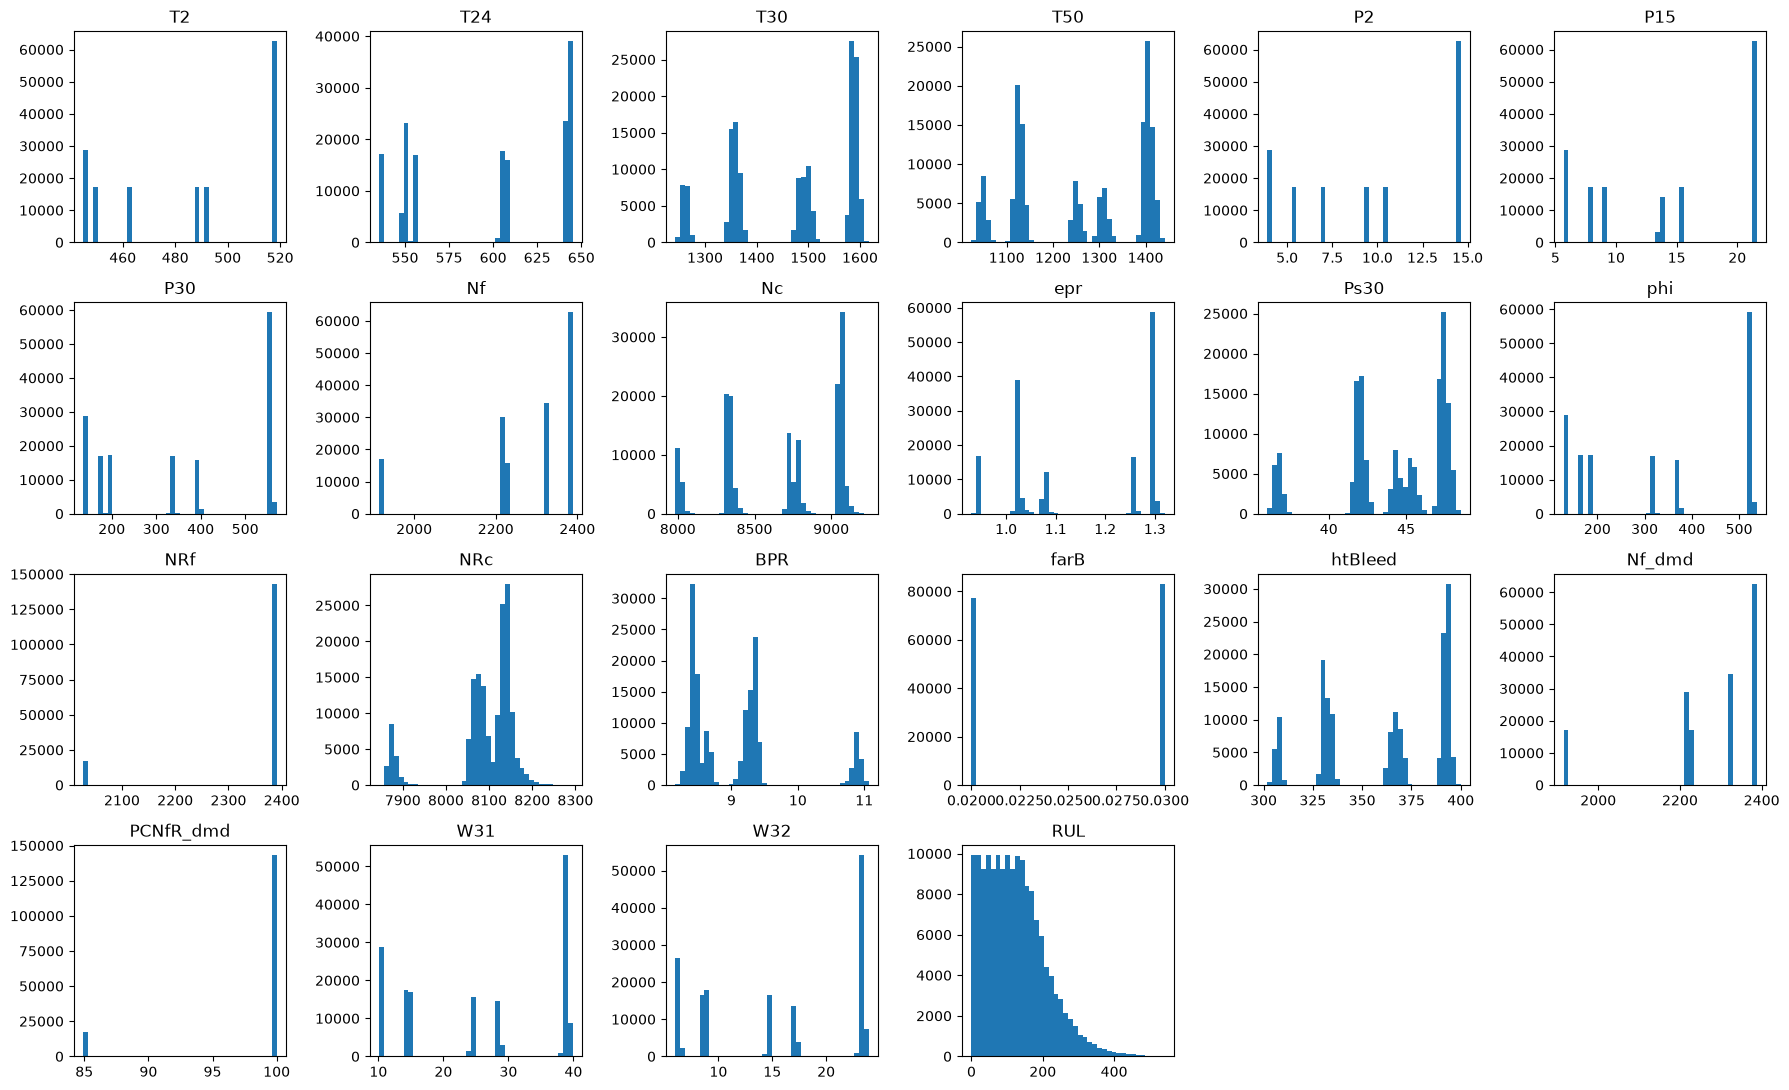

In [65]:
import matplotlib.pyplot as plt

fig, ejes = plt.subplots(4, 6, figsize=(18, 11))
ejes = ejes.ravel()
for ax, col in zip(ejes, SENSORES + ["RUL"]):
    ax.hist(train[col], bins=40)
    ax.set_title(col)
for ax in ejes[len(SENSORES) + 1:]:
    ax.axis("off")
plt.tight_layout()
plt.savefig("Images/Histograma de sensores.png", dpi=300, bbox_inches="tight" )
plt.show()


In [73]:
FD004 = pd.read_csv(DATOS / "test_FD004.txt", sep=r"\s+", header=None, names=COLUMNAS)

FD004

,engine,cycle,op_setting_1,op_setting_2,op_setting_3,T2,T24,T30,T50,P2,...,phi,NRf,NRc,BPR,farB,htBleed,Nf_dmd,PCNfR_dmd,W31,W32
0,1,1,20.0072,0.7000,100.0,491.19,606.67,1481.04,1227.81,9.35,...,313.03,2387.78,8048.98,9.2229,0.02,362,2324,100.00,24.31,14.7007
1,1,2,24.9984,0.6200,60.0,462.54,536.22,1256.17,1031.48,7.05,...,163.61,2028.09,7863.46,10.8632,0.02,306,1915,84.93,14.36,8.5748
2,1,3,42.0000,0.8420,100.0,445.00,549.23,1340.13,1105.88,3.91,...,129.98,2387.95,8071.13,9.3960,0.02,328,2212,100.00,10.39,6.4365
3,1,4,42.0035,0.8402,100.0,445.00,549.19,1339.70,1107.26,3.91,...,129.48,2387.90,8078.89,9.3594,0.02,328,2212,100.00,10.56,6.2367
4,1,5,35.0079,0.8400,100.0,449.44,555.10,1353.04,1117.80,5.48,...,181.82,2387.87,8057.83,9.3030,0.02,333,2223,100.00,14.85,8.9326
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41209,248,277,41.9991,0.8401,100.0,445.00,550.30,1364.40,1129.17,3.91,...,130.87,2388.50,8112.61,9.4427,0.02,331,2212,100.00,10.53,6.2620
41210,248,278,20.0026,0.7005,100.0,491.19,608.00,1494.75,1260.88,9.35,...,314.51,2388.33,8086.83,9.2772,0.02,366,2324,100.00,24.33,14.6486
41211,248,279,34.9988,0.8413,100.0,449.44,555.92,1370.65,1130.97,5.48,...,182.76,2388.64,8100.84,9.3982,0.02,336,2223,100.00,14.69,8.8389
41212,248,280,20.0027,0.7000,100.0,491.19,608.19,1489.11,1256.25,9.35,...,314.17,2388.37,8085.24,9.2727,0.03,366,2324,100.00,24.44,14.6887


In [75]:
ciclos_por_motor = (
    train.groupby(["subset", "engine", "engine_id"], as_index=False)
         .agg(total_ciclos=("cycle", "count"))
         .drop(columns="engine")
)
ciclos_por_motor

,subset,engine_id,total_ciclos
0,FD001,FD001_1,192
1,FD001,FD001_2,287
2,FD001,FD001_3,179
3,FD001,FD001_4,189
4,FD001,FD001_5,269
...,...,...,...
704,FD004,FD004_245,205
705,FD004,FD004_246,161
706,FD004,FD004_247,211
707,FD004,FD004_248,184


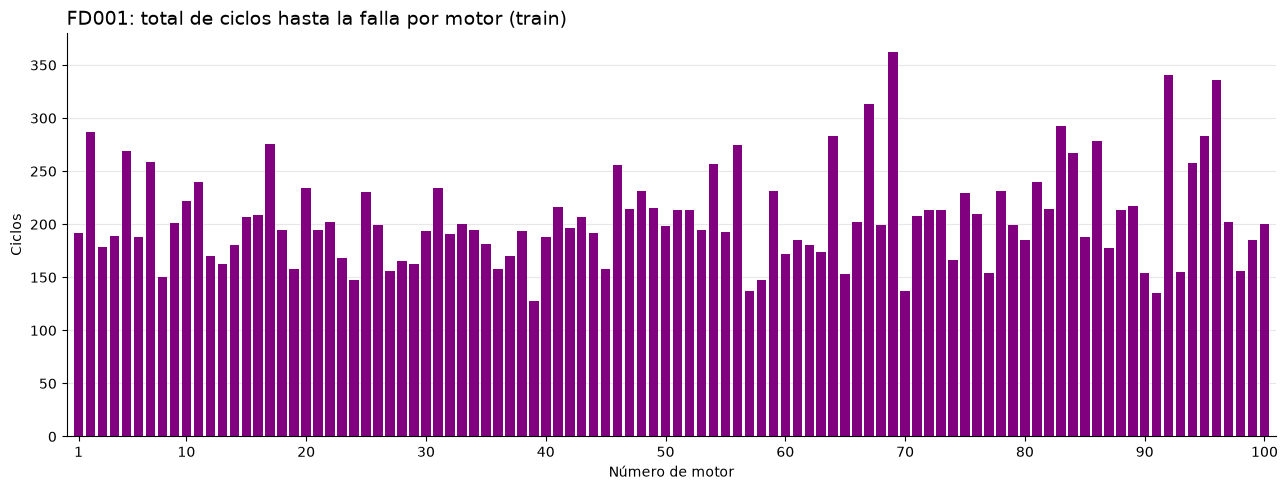

In [78]:
fd001 = ciclos_por_motor[ciclos_por_motor["subset"] == "FD001"]
numero_motor = fd001["engine_id"].str.split("_").str[1].astype(int)

fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(numero_motor, fd001["total_ciclos"], width=0.8, color="purple")

ax.set_title("FD001: total de ciclos hasta la falla por motor (train)", loc="left", fontsize=14)
ax.set_xlabel("Número de motor")
ax.set_ylabel("Ciclos")
ax.set_xticks([1] + list(range(10, 101, 10)))
ax.set_xlim(0, 101)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("Images/Ciclos por motor FD001.png", dpi=1500, bbox_inches="tight")
plt.show()

In [79]:
total_fd001 = (train["subset"] == "FD001").sum()
print(f"Total de instancias en FD001 (train): {total_fd001:,}")

Total de instancias en FD001 (train): 20,631


In [80]:
print(train["subset"].value_counts().sort_index())

subset
FD001    20631
FD002    53759
FD003    24720
FD004    61249
Name: count, dtype: int64


## Tipos de datos, número de instancias y atributos

Cada instancia corresponde a un ciclo de operación de un motor. El dataset no tiene valores nulos ni filas duplicadas.

### Número de instancias

| Subset | Instancias train | Motores train | Instancias test | Motores test |
|---|---:|---:|---:|---:|
| FD001 | 20,631 | 100 | 13,096 | 100 |
| FD002 | 53,759 | 260 | 33,991 | 259 |
| FD003 | 24,720 | 100 | 16,596 | 100 |
| FD004 | 61,249 | 249 | 41,214 | 248 |
| **Total** | **160,359** | **709** | **104,897** | **707** |

En total hay 265,256 instancias y 1,416 motores. Los archivos `RUL_FD00X.txt` contienen 707 valores: el RUL real de cada motor de test en su último ciclo registrado.

### Número de atributos

Los archivos originales tienen 26 columnas. Durante la carga se agregan `subset` y `engine_id` en ambos conjuntos, y `RUL` solo en train. Por eso, train queda con 29 columnas y test con 28.

| Atributos | Cantidad | Tipo en pandas | Tipo de dato | Rol |
|---|---:|---|---|---|
| `subset`, `engine_id` | 2 | `str` | Categórico nominal | Identificadores agregados |
| `engine` | 1 | `int64` | Categórico nominal | Identificador |
| `cycle` | 1 | `int64` | Numérico discreto | Tiempo |
| `op_setting_1`, `op_setting_2` | 2 | `float64` | Numérico continuo | Condición de operación |
| `op_setting_3` | 1 | `float64` | Numérico discreto | Condición de operación |
| Sensores decimales (19) | 19 | `float64` | Numérico continuo | Medición |
| `htBleed`, `Nf_dmd` | 2 | `int64` | Numérico discreto | Medición |
| `RUL` (solo train) | 1 | `int64` | Numérico discreto | Variable objetivo |

Train tiene 22 columnas `float64`, 5 `int64` y 2 `str`. Test tiene 22 `float64`, 4 `int64` y 2 `str`.